# 02 · Forecasting Models

**Task:** at hour *t*, predict the electricity price at hour *t + 24*.

**Rules we follow (lessons from the EDA):**
- Only use information available at least 24 hours before the target hour → no data leakage.
- Split by time: train on **2015–2017**, test on **2018** (a full year the model has never seen).
- Always compare against simple baselines. A complex model is only worth it if it beats them.

In [1]:
import sys
import json
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

from src.features.build import OFFICIAL_FORECAST, TARGET, build_features
from src.models.train import (
    TEST_START, regression_metrics, save_model, time_split, train_lightgbm, train_ridge,
)
from src.plot_style import PALETTE, TEXT_SECONDARY, apply_style

apply_style()
FIG_DIR = Path("../reports/figures")

df = pd.read_parquet("../data/processed/energy_weather.parquet")

## 1. Features

`build_features()` (in `src/features/build.py`) creates four groups of features:

| Group | Examples | Why it is allowed |
|---|---|---|
| Calendar | hour, weekday, month, holiday, sin/cos encodings | always known in advance |
| Day-ahead forecasts | load, wind and solar forecasts, residual load | published the day before |
| Lags | price 24h / 48h / 168h ago, rolling means, yesterday's generation & weather | already observed |
| Official price forecast | `price_day_ahead` | published the day before (optional) |

In [2]:
X, y = build_features(df, include_official_forecast=True)
X_train, X_test, y_train, y_test = time_split(X, y, TEST_START)

print(f"Features: {X.shape[1]}")
print(f"Train: {X_train.index.min():%Y-%m-%d} → {X_train.index.max():%Y-%m-%d}  ({len(X_train):,} hours)")
print(f"Test:  {X_test.index.min():%Y-%m-%d} → {X_test.index.max():%Y-%m-%d}  ({len(X_test):,} hours)")
X.columns.tolist()

Features: 29
Train: 2015-01-08 → 2017-12-31  (26,111 hours)
Test:  2018-01-01 → 2018-12-31  (8,760 hours)


['hour',
 'day_of_week',
 'month',
 'day_of_year',
 'is_weekend',
 'is_holiday',
 'hour_sin',
 'hour_cos',
 'doy_sin',
 'doy_cos',
 'total_load_forecast',
 'forecast_wind_onshore_day_ahead',
 'forecast_solar_day_ahead',
 'residual_load_forecast',
 'price_lag_24h',
 'price_lag_48h',
 'price_lag_72h',
 'price_lag_168h',
 'price_mean_24h',
 'price_mean_7d',
 'price_std_24h',
 'price_min_24h',
 'price_max_24h',
 'fossil_generation_lag_24h',
 'wind_generation_lag_24h',
 'load_actual_lag_24h',
 'temp_mean_lag_24h',
 'wind_speed_mean_lag_24h',
 'price_day_ahead']

## 2. Baselines

1. **Naive (24h):** tomorrow's price at this hour = today's price at this hour.
2. **Seasonal naive (168h):** same hour, one week ago.
3. **Official forecast:** the grid operator's day-ahead price.

In [3]:
results = {
    "Naive (24h ago)": regression_metrics(y_test, X_test["price_lag_24h"]),
    "Seasonal naive (1 week ago)": regression_metrics(y_test, X_test["price_lag_168h"]),
    "Official day-ahead forecast": regression_metrics(y_test, X_test[OFFICIAL_FORECAST]),
}
pd.DataFrame(results).T.round(2)

,MAE,RMSE,Bias
Naive (24h ago),5.21,7.70,0.11
Seasonal naive (1 week ago),6.39,9.64,0.35
Official day-ahead forecast,8.86,11.89,6.15


**Surprise:** the naive "same as yesterday" forecast (MAE ≈ 5.2) is much better than the official forecast (MAE ≈ 8.9).

Why? The official figure is the *day-ahead market* price, while `price_actual` is the final price, which includes
additional components and is systematically ≈ 6–8 € higher. So the official number is not really trying to predict
`price_actual`. **The honest benchmark to beat is therefore the naive 24h baseline, not the official forecast.**

## 3. Models

- **Ridge regression**: a linear model, the simplest learned baseline.
- **LightGBM**: gradient-boosted trees; captures non-linear effects and interactions (e.g. *wind matters more in winter evenings*).

We train each model twice, with and without the official forecast as a feature, to measure how much it adds.

In [4]:
models = {}
predictions = {}

for with_official in [False, True]:
    Xf, yf = build_features(df, include_official_forecast=with_official)
    Xtr, Xte, ytr, yte = time_split(Xf, yf, TEST_START)
    suffix = "" if with_official else " (no official fcst)"

    for name, train_fn in [("Ridge", train_ridge), ("LightGBM", train_lightgbm)]:
        model = train_fn(Xtr, ytr)
        key = name + suffix
        models[key] = model
        predictions[key] = pd.Series(model.predict(Xte), index=Xte.index)
        results[key] = regression_metrics(yte, predictions[key])

results_df = pd.DataFrame(results).T.sort_values("MAE").round(2)
naive_mae = results_df.loc["Naive (24h ago)", "MAE"]
results_df["Improvement vs naive"] = (1 - results_df["MAE"] / naive_mae).map("{:+.0%}".format)
results_df

,MAE,RMSE,Bias,Improvement vs naive
LightGBM,3.80,5.40,-0.96,+27%
Ridge,4.04,5.75,-0.88,+22%
LightGBM (no official fcst),4.16,5.93,0.78,+20%
Ridge (no official fcst),4.22,5.97,0.59,+19%
Naive (24h ago),5.21,7.70,0.11,+0%
Seasonal naive (1 week ago),6.39,9.64,0.35,-23%
Official day-ahead forecast,8.86,11.89,6.15,-70%


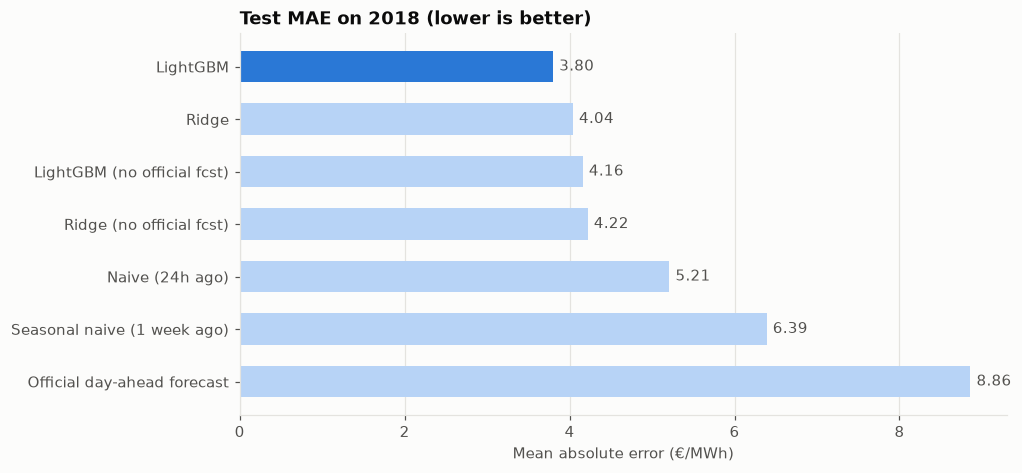

In [5]:
order = results_df.sort_values("MAE", ascending=False)
best = order.index[-1]
colors = [PALETTE[0] if name == best else "#b7d3f6" for name in order.index]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(order.index, order["MAE"], color=colors, height=0.6)
ax.bar_label(bars, fmt="%.2f", padding=4, color=TEXT_SECONDARY)
ax.set_title("Test MAE on 2018 (lower is better)")
ax.set_xlabel("Mean absolute error (€/MWh)")
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "model_comparison.png")
plt.show()

## 4. A closer look at the best model

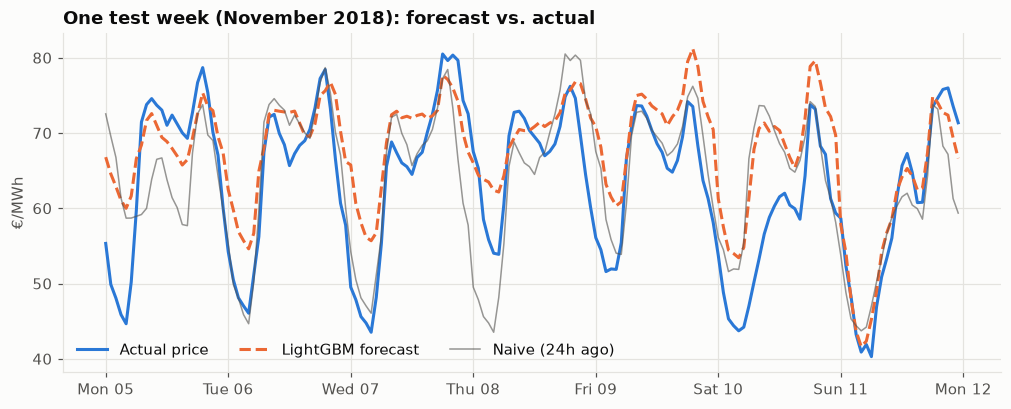

In [6]:
best_pred = predictions["LightGBM"]
week = slice("2018-11-05", "2018-11-11")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y_test[week].index, y_test[week], color=PALETTE[0], linewidth=2, label="Actual price")
ax.plot(best_pred[week].index, best_pred[week], color=PALETTE[1], linewidth=2, linestyle="--", label="LightGBM forecast")
ax.plot(X_test.loc[week, "price_lag_24h"].index, X_test.loc[week, "price_lag_24h"], color=TEXT_SECONDARY,
        linewidth=1, alpha=0.6, label="Naive (24h ago)")
ax.set_title("One test week (November 2018): forecast vs. actual")
ax.set_ylabel("€/MWh")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d", tz=y_test.index.tz))
ax.legend(loc="lower left", ncols=3)
fig.savefig(FIG_DIR / "forecast_week.png")
plt.show()

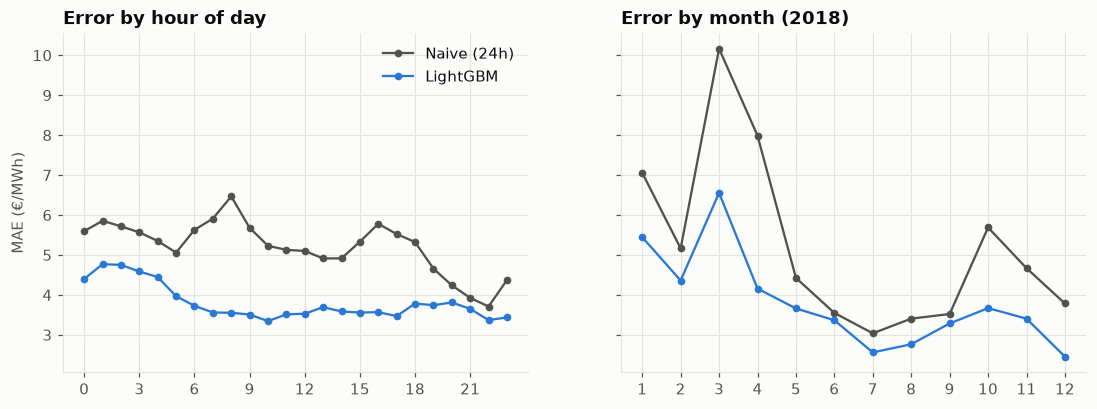

In [7]:
abs_err = (y_test - best_pred).abs()
naive_err = (y_test - X_test["price_lag_24h"]).abs()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, key, title, ticks in [
    (axes[0], abs_err.index.hour, "Error by hour of day", range(0, 24, 3)),
    (axes[1], abs_err.index.month, "Error by month (2018)", range(1, 13)),
]:
    ax.plot(naive_err.groupby(key).mean(), color=TEXT_SECONDARY, marker="o", markersize=4, label="Naive (24h)")
    ax.plot(abs_err.groupby(key).mean(), color=PALETTE[0], marker="o", markersize=4, label="LightGBM")
    ax.set_title(title)
    ax.set_xticks(list(ticks))
axes[0].set_ylabel("MAE (€/MWh)")
axes[0].legend()
plt.show()

## 5. Which features does the model rely on?

LightGBM's built-in *gain* importance shows how much each feature reduces the error across all trees.
(In the next notebook we use SHAP for a more reliable, per-prediction explanation.)

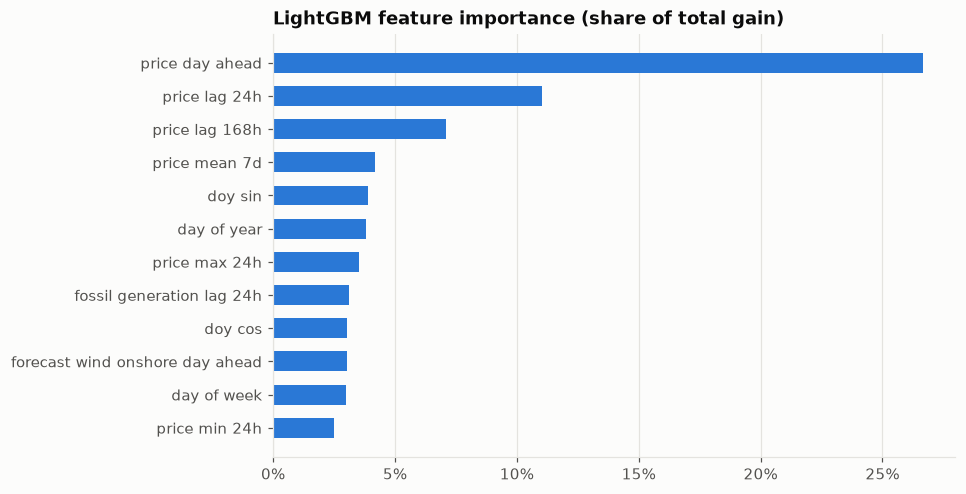

In [8]:
lgbm = models["LightGBM"]
importance = pd.Series(lgbm.booster_.feature_importance("gain"), index=lgbm.feature_name_)
importance = (importance / importance.sum()).sort_values().tail(12)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index.str.replace("_", " "), importance.values, color=PALETTE[0], height=0.6)
ax.set_title("LightGBM feature importance (share of total gain)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "feature_importance.png")
plt.show()

## 6. Save the model and results

In [9]:
save_model(models["LightGBM"], "lightgbm_price_24h")
# Fundamentals-only model, used by the agent for what-if scenarios
save_model(models["LightGBM (no official fcst)"], "lightgbm_price_24h_fundamentals")

metrics_path = Path("../reports/metrics.json")
metrics_path.write_text(json.dumps(pd.DataFrame(results).T.round(3).to_dict(orient="index"), indent=2))
print("Saved model and", metrics_path)

Saved model and ..\reports\metrics.json


## Key findings

1. **Beat the right baseline.** The official day-ahead price is a weak benchmark for `price_actual` (it is biased by ≈ 6 €).
   The naive "same hour yesterday" forecast is much stronger, so that is what we measure against.
2. **LightGBM reduces the error by ~27 % vs. the naive baseline** (MAE ≈ 3.8 vs 5.2 €/MWh on the unseen year 2018).
3. **A linear model gets surprisingly close** (Ridge MAE ≈ 4.0). Most of the signal is in a few strong features
   (the official forecast and recent prices), and trees add a smaller extra gain from non-linear effects.
4. **The official forecast still helps as a feature** (≈ 0.35 €/MWh lower MAE): even if it is biased,
   its *shape* carries information about tomorrow's market.

**Next:** explain individual predictions with SHAP, and test statistically (in R) whether wind lowers prices.